In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.preprocessing import LabelEncoder


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

import os


downloads = os.path.expanduser("/Users/arnav/Desktop/Python/sleepdisorder/input/")

for dirname, _, filenames in os.walk(downloads):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/Users/arnav/Desktop/Python/sleepdisorder/input/Sleep_health_and_lifestyle_dataset.csv


In [2]:
df = pd.read_csv("/Users/arnav/Desktop/Python/sleepdisorder/input/Sleep_health_and_lifestyle_dataset.csv")

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [3]:
#splitting up the blood pressure into the high and low
df[['Systolic BP', 'Diastolic BP']] = df["Blood Pressure"].str.split("/", expand=True)

#turning the values into integers
df['Systolic BP'] = df['Systolic BP'].astype(int)
df['Diastolic BP'] = df['Diastolic BP'].astype(int)

#deletes a Blood pressure column, axis 1 means the y axis and 0 means the x axis, inplace True means the original df is changed
df.drop(['Blood Pressure'], axis=1, inplace=True)

#prints the first 5 lines of the table
df.head()


,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic BP,Diastolic BP
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,NaN,126,83
1,2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,NaN,125,80
2,3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,NaN,125,80
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


In [4]:
#gives the information on the type (str, int, float), null or non-null, storage, index and total # of people, etc
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    str    
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    str    
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    str    
 9   Heart Rate               374 non-null    int64  
 10  Daily Steps              374 non-null    int64  
 11  Sleep Disorder           155 non-null    str    
 12  Systolic BP              374 non-null    int64  
 13  Diastolic BP             374 non-null    int64  
dtypes: float64(1), int64(9), str(4)
memor

In [5]:
#tells how many total responses for each column were left blank
df.isnull().sum()

Person ID                    0
Gender                       0
Age                          0
Occupation                   0
Sleep Duration               0
Quality of Sleep             0
Physical Activity Level      0
Stress Level                 0
BMI Category                 0
Heart Rate                   0
Daily Steps                  0
Sleep Disorder             219
Systolic BP                  0
Diastolic BP                 0
dtype: int64

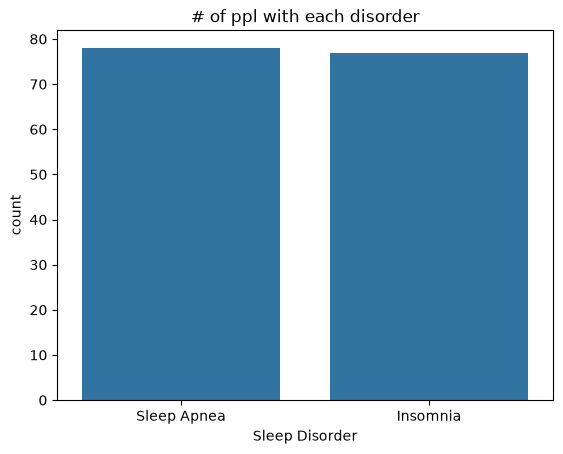

In [6]:
sns.countplot(x="Sleep Disorder", data=df)
plt.title("# of ppl with each disorder")
plt.show()

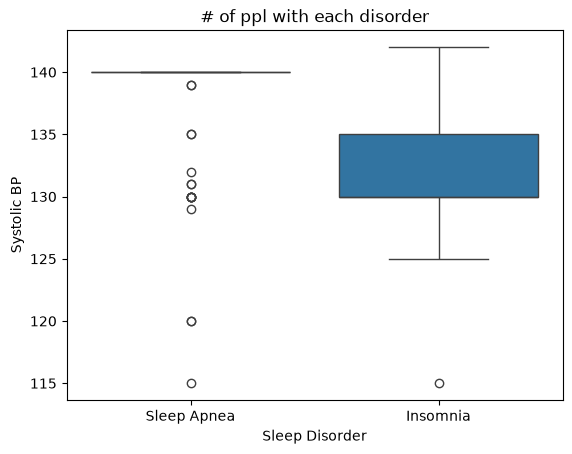

In [7]:
sns.boxplot(x="Sleep Disorder", y="Systolic BP", data=df)
plt.title("# of ppl with each disorder")
plt.show()

In [8]:
#adds the word "none" to all of the sleep disorder responses that are empty
df['Sleep Disorder'] = df["Sleep Disorder"].fillna('None')

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic BP,Diastolic BP
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,3,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


In [9]:
###This entire block is to turn all of the columns with verbal values (eg for "Gender", you get a word response) into integers to easily use ML
#this is an empty dictionary, lbl_encoders
lbl_encoders = {}

for clmn in df.columns:    #iterates over each column
    
    if df[clmn].dtype in ["object", "str"]:   #if the column has strings
        le = LabelEncoder()           #this is a class from Scikit learn that has a built-in program to use the fit and col functions
        df[clmn] = le.fit_transform(df[clmn]) # ***KEY PART!*** the fit function looks for all of the unique values, and the tranform assigns them a number
        lbl_encoders[clmn] = le # ALSO IMPORTANT!! This line assigns a key and value for the dictionary, so you can re-retrieve the acual strings instead of numbers


df.info() #testing to ssee if it worked (took many tries)

<class 'pandas.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    int64  
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    int64  
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    int64  
 9   Heart Rate               374 non-null    int64  
 10  Daily Steps              374 non-null    int64  
 11  Sleep Disorder           374 non-null    int64  
 12  Systolic BP              374 non-null    int64  
 13  Diastolic BP             374 non-null    int64  
dtypes: float64(1), int64(13)
memory usage

In [20]:
# NEEDED FOR THE TRAIN/TEST CELL BELOW: initializing the arrays X and y to get data from
X = df.drop("Sleep Disorder", axis = 1) # This means the X (featues only) has all of the data except the data for thing we are predicting, Sleep Disorder
y = df["Sleep Disorder"] # This means the y (prediction values only) has the data of the thing we are predicting, Sleep Disorder

In [21]:
### One of THE most important steps in Data Analysis and prediction making!
# the X means features/inputs, the y means the actual thing the machine is predicting (sleep disorder)
# train is the model's learning info, test is where the model checks how accurate it was
X_train, X_test, y_train, y_test = train_test_split( #calls the train_test_split function from sklearn and assigns 4 variables with values:
    X, y, # the arrays X and Y need to be written once in the brackets to tell where to get the data from
    test_size = 0.2, #this means that AI is using 20 percent of the data in the test set (the rest 80 percent is for training the model)
    random_state = 42 #this ensures that everyone who tries the program will still get the same result: still random, just decided random (42 is just commonly used, but can be any number)
)

In [22]:
#this is where we actually train the model: rfc basically uses logical thinking to create branched questions (response leads to other options): eg is the sleep over 7 hrs? yes/no if no, maybe sleep apnea, etc.
rf = RandomForestClassifier(n_estimators=200) # the var. makes it easier to read overall, and n=200 means there are 200 branches/trees of testing for data to train: like a forest!
rf.fit(X_train, y_train) #the fit function means the X_train and y_train are taking part of the "learning": X_train has the clues/info, y_train has the correct answer: they associate the info with the answer


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [25]:
# Use the trained rf model to predict the Disorders given the test data
# X_test contains new data the model has never seen before.
# The predictions are stored in y_pred and will later be compared to y_test to measure model accuracy.
y_pred = rf.predict(X_test)

In [26]:
#This is to get us the accuracy of the model from its test predictions to the actual key
print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred)) #this gives us a report of how it did

Accuracy: 0.88
              precision    recall  f1-score   support

           0       0.72      0.81      0.76        16
           1       0.95      0.98      0.97        43
           2       0.85      0.69      0.76        16

    accuracy                           0.88        75
   macro avg       0.84      0.83      0.83        75
weighted avg       0.88      0.88      0.88        75



In [15]:
#This is the actual use of training the model! Here, I am creating a function that can actually give you the machine's prediction for secific people.
def predict_sleep(data):   #Regular Func. notation, data is the parameter
    data = pd.DataFrame(   #Sklearn can't read a Python list in this form, so we need pandas to turn it into a new df.
        [data], #suppose the user gives a list of numbers. You need an array, so you put the list in a list by putting brackets around data
        columns = X.columns #This tells the pandas that the columns which the data goes into (from line above) are the same columns as used with X during train/test/split
    )

    prediction = rf.predict(data) #the machine predicts in this line here, but the prediction is still in number form!
    prediction_actualname = lbl_encoders["Sleep Disorder"].inverse_transform(prediction) #this inverses the number from sleep disorders back into a word, then stored it under the variable actualname

    return prediction_actualname[0] #the variable is technically a list so insstead of returning ["Sleep Apnea"] it should return Sleep Apnea, and same for the other options.


In [16]:
sample = X_test.iloc[2] # TAKES DATA FROM LINE 5 BCUZ OF ILOC

print(predict_sleep(sample))

None
